# PR4 IA. EL PROBLEMA DE LA MOCHILA
# MARIO ROSELL GARCÍA - XIANG LIN

## FASE 0 · LECTURA DEL EJERICICIO RESUELTO

Tras leer el ejercicio resuelto comprendemos la estructura intrínseca y el objetivo de este ejercicio. 

Pretendemos ejecutar un algoritmo genético sobre el famoso problema de la mochila. Esa parte es la fácil, lo complicado será realizar un método científico donde obtengamos los parámetros que maximicen el resultado obtenido en cada ejecución. 

## FASE 1 · IMPLEMENTACIÓN

Primero cargaremos los datos, que incluyen el peso y valor de todos los objetos, junto a su índice de valor por unidad de peso. 
Esta lista de índices es ordenada de menor a mayor para realizar la reparación más óptima posible. 

El calculo de la aptitud tiene incluido la reparación o penalización, devolviendo también un segundo parámetro que dice si los valores son válidos. 
Esto es debido a que cuando penalizamos, aunque se le da una puntuación menor que la que debería tener, puede que se considere como el mejor de una generación. 
Para evitar eso, pero poder usarlo en los cruces, es que añadimos esta variable. 

In [1]:
import random
import statistics
import math
import itertools
import csv
import os
import json

C = 2457
PRESUPUESTO = 2000
OPTIMO_TEORICO = 2981

def cargarDatos():
    pesos, valores, indices = [], [], []
    with open("mochila_P4.csv") as f:
        for cont, r in enumerate(csv.DictReader(f)):
            p, v = int(r['peso']), int(r['valor'])
            pesos.append(p)
            valores.append(v)
            indices.append((v / p, cont))
    indices.sort(key=lambda x: x[0])
    numObjetos = len(pesos)
    
    return {"pesos": pesos, "valores": valores, "indices": indices, "n" : numObjetos}

# Aptitud con penalizacion o reparacion integrada. 
def aptitud(x, datos, tipo = ("reparacion", 0)):
    valor = sum(datos["valores"][i] if x[i] == 1 else 0 for i in range(len(x)))
    peso = sum(datos["pesos"][i] if x[i] == 1 else 0 for i in range(len(x)))

    if peso <= C: return valor, True
    
    if tipo[0] == "penalizacion": return max(0, valor - (peso - C) * tipo[1]), False

    cont = 0 #reparacion
    while peso > C:
        ind = datos["indices"][cont][1]
        if x[ind] == 1: 
            peso -= datos["pesos"][ind]
            valor -= datos["valores"][ind]
            x[ind] = 0
        cont += 1   
    return valor, True


def peso(x, datos):
    return sum(datos["pesos"][i] if x[i] == 1 else 0 for i in range(len(x)))

# Utilidades para leer y escribir cadenas como en el documento
def bits(cadena):
    return [int(c) for c in cadena if c in "01"]

def texto(x):
    s = "".join(map(str, x))
    return " ".join(s[i:i + 4] for i in range(0, len(s), 4))

datos = cargarDatos()

Tenemos una pequeña porción de código que usaremos para escribir las configuraciones en los csv.

In [2]:
ARCHIVO_RESULTADOS = "resultados.csv"

def guardar_resultado(fase, configuracion, semilla, valor, peso_solucion, evaluaciones):
    archivo_nuevo = (not os.path.exists(ARCHIVO_RESULTADOS) or os.path.getsize(ARCHIVO_RESULTADOS) == 0)

    with open(ARCHIVO_RESULTADOS, "a", newline="", encoding="utf-8") as f:
        escritor = csv.writer(f)

        if archivo_nuevo:
            escritor.writerow(["fase", "configuracion", "semilla", "valor", "peso", "evaluaciones"])

        escritor.writerow([fase,configuracion,semilla,valor,peso_solucion,evaluaciones])

Añadimos el resto de piezas del genético, que van a usar el principalmente la función aptitud anterior.

Debemos tener cuidado en torneo y elite, pues la aptitud tiene también el booleano de validez. Sin embargo, en estas funciones eso no importa. 
Solo importa cuando queramos marcar una mochila como la mejor de una generación. 

In [3]:
def poblacion_inicial(P, datos, rng):
    return [[rng.randint(0, 1) for _ in range(datos["n"])] for _ in range(P)]

def torneo(apt, k, rng):
    candidatos = rng.sample(range(len(apt)), k)
    return max(candidatos, key=lambda i: apt[i][0])

def cruce_un_punto(a, b, corte):
    return a[:corte] + b[corte:], b[:corte] + a[corte:]

def cruce_uniforme(a, b, mascara):
    h1 = [a[i] if mascara[i] else b[i] for i in range(len(a))]
    h2 = [b[i] if mascara[i] else a[i] for i in range(len(a))]
    return h1, h2

def cruzar(a, b, pc, tipo, rng):
    n = len(a)
    if rng.random() < pc:
        if tipo == "un_punto":
            return cruce_un_punto(a, b, rng.randint(1, n - 1))
        mascara = [rng.random() < 0.5 for _ in range(n)]
        return cruce_uniforme(a, b, mascara)
    return a[:], b[:]

def mutar(x, pm, rng):
    return [1 - g if rng.random() < pm else g for g in x]

def elite(apt, e):
    orden = sorted(range(len(apt)), key=lambda i: -apt[i][0])
    return orden[:e]

Y por último, el algorítmo genético completo. 
Cuenta con el tipo de penalizacion para la aptitud.

Tal y como pide el enunciado, por cada ejecución podemos mantener la configuración y la semilla al llamar al genético.

El genético, al finalizar, nos da el mejor valor factible (o sea, valido) y el peso de este. 

El número de evaluaciones usadas siempre será el máximo que se permitan, porque el código nunca sabe cuando ha llegado al óptimo.  

In [4]:
def genetico(datos, tipoAptitud = ("reparacion", 0), presupuesto=PRESUPUESTO, P=50, pc=0.9, pm=None, k=2, e=1, 
             cruce="un_punto", semilla=0, generaciones=None, historial=False):
    rng = random.Random(semilla)
    pm = 1 / datos["n"] if pm is None else pm
    if generaciones is not None:
        presupuesto = math.inf  

        
    pob = poblacion_inicial(P, datos, rng)
    apt = [aptitud(x, datos, tipoAptitud) for x in pob]
    evals = P

    mejor = 0
    mejor_peso = 0
    for h, (f, valido) in zip(pob, apt):
        if valido and f > mejor:
            mejor = f
            mejor_peso = peso(h, datos)

    hist = [(evals, mejor)]
    g = 0

    while evals < presupuesto and (generaciones is None or g < generaciones):
        # Elitismo: los e mejores pasan sin cambios ni nueva evaluación
        idx = elite(apt, e)
        nueva, nueva_apt = [pob[i] for i in idx], [apt[i] for i in idx]

        while len(nueva) < P and evals < presupuesto:
            a = pob[torneo(apt, k, rng)]
            b = pob[torneo(apt, k, rng)]
            for h in cruzar(a, b, pc, cruce, rng):
                if len(nueva) >= P or evals >= presupuesto:
                    break                       # el hijo que sobra no se evalúa
                h = mutar(h, pm, rng)
                f, valido = aptitud(h, datos, tipoAptitud); evals += 1
                nueva.append(h); nueva_apt.append((f, valido))
                if valido and f > mejor:
                    mejor = f
                    mejor_peso = peso(h, datos)
                    hist.append((evals, mejor))

        if len(nueva) < P:                      # el presupuesto se acabó a media generación
            break
        pob, apt = nueva, nueva_apt
        g += 1

    hist.append((evals, mejor))
    return (mejor, mejor_peso, evals, hist) if historial else (mejor, mejor_peso, evals)

## FASE 2 · HIPÓTESIS

Vamos a estudiar como influyen todos los parámetros del algorítmo genético, pero previamente expresaremos nuestras hipótesis.



### H1. Tamaño de la población (P)

**Hipótesis.** Aumentar el tamaño de la población reducirá el *gap* medio, al menos hasta cierto punto.

**Razonamiento.** Una población más grande proporciona una mayor diversidad de soluciones iniciales y permite explorar más combinaciones de objetos. Sin embargo, como el presupuesto está limitado a 2000 evaluaciones, una población demasiado grande dejará menos evaluaciones disponibles para generar nuevas generaciones y mejorar las soluciones.

**Cómo la comprobaremos.** Compararemos varios tamaños de población manteniendo constantes el resto de los parámetros y utilizaremos el *gap* medio de las ejecuciones como medida principal.

---

### H2. Probabilidad de mutación (pm)

**Hipótesis.** Una probabilidad de mutación moderada producirá un *gap* menor que una probabilidad demasiado baja o demasiado alta.

**Razonamiento.** Si la mutación es poco frecuente, el algoritmo puede perder diversidad y quedarse estancado en soluciones de calidad mejorable. En cambio, si es demasiado frecuente, puede alterar excesivamente las soluciones y dificultar la conservación de combinaciones de objetos que ya funcionan bien.

**Cómo la comprobaremos.** Probaremos diferentes probabilidades de mutación, manteniendo los demás parámetros fijos, y compararemos el *gap* medio obtenido.

---

### H3. Tamaño del torneo (k)

**Hipótesis.** Aumentar el tamaño del torneo mejorará inicialmente los resultados, pero un tamaño excesivo podría aumentar el *gap*.

**Razonamiento.** Con torneos más grandes, los individuos con mayor aptitud tienen más posibilidades de ser seleccionados, favoreciendo la transmisión de buenas soluciones. No obstante, una presión de selección demasiado elevada puede reducir la diversidad de la población y provocar una convergencia prematura.

**Cómo la comprobaremos.** Ejecutaremos el algoritmo con distintos tamaños de torneo y compararemos sus *gaps* medios, manteniendo constantes los demás factores.

---

### H4. Tratamiento de la restricción de capacidad

**Hipótesis.** La reparación de las soluciones que superan la capacidad de la mochila obtendrá un *gap* medio menor que la penalización de las soluciones no factibles.

**Razonamiento.** La reparación transforma una solución que supera el peso máximo en otra que cumple la restricción y puede seguir siendo útil para la búsqueda. Por el contrario, la penalización reduce la aptitud de las soluciones que incumplen la capacidad, pero no garantiza por sí sola que se generen suficientes soluciones factibles de buena calidad. El resultado también dependerá de cómo se implemente la reparación y del valor de la penalización.

**Cómo la comprobaremos.** Compararemos ambos tratamientos manteniendo constantes los demás parámetros y utilizando únicamente soluciones factibles para calcular el mejor valor y el *gap* de cada ejecución.

---

### H5. Interacción entre el tamaño de la población (P) y la probabilidad de mutación (pm)

**Hipótesis.** El efecto de la probabilidad de mutación sobre el *gap* dependerá del tamaño de la población; en particular, una población pequeña podría beneficiarse más de aumentar la mutación que una población grande.

**Razonamiento.** Una población pequeña dispone de menos diversidad inicial y puede necesitar más mutación para explorar nuevas combinaciones. Una población grande puede conservar más diversidad por sí misma, por lo que una mutación elevada podría resultar innecesaria e incluso perjudicial. Por tanto, no esperamos que exista necesariamente una única probabilidad de mutación óptima para todos los tamaños de población.

**Cómo la comprobaremos.** Combinaremos varios tamaños de población con distintas probabilidades de mutación y compararemos los *gaps* medios de todas las combinaciones.

---

### H6. Probabilidad de cruce (pc)

**Hipótesis.** Una probabilidad de cruce alta producirá un *gap* medio menor que una probabilidad de cruce baja, siempre que la mutación y el resto de los parámetros se mantengan adecuados.

**Razonamiento.** El cruce permite combinar partes de dos soluciones y aprovechar características favorables que hayan aparecido en distintos individuos. Si se aplica muy poco, el algoritmo dependerá en mayor medida de la selección y la mutación para generar nuevas combinaciones. Sin embargo, el cruce no garantiza una mejora, ya que también puede separar combinaciones de objetos que resultaban beneficiosas.

**Cómo la comprobaremos.** Compararemos distintas probabilidades de cruce manteniendo constantes el resto de los parámetros y calcularemos el *gap* medio de las ejecuciones.

---

### Criterio común de evaluación

Todas las hipótesis se contrastarán mediante **30 ejecuciones por configuración**, utilizando las mismas semillas para las configuraciones comparadas y respetando el presupuesto de **2000 evaluaciones por ejecución**.

Consideraremos que un menor *gap* medio indica un mejor resultado y tendremos en cuenta la variabilidad entre ejecuciones para no atribuir a un factor diferencias que puedan deberse al azar.





## FASE 3 · DISEÑO

### Configuracion base

Tal y como se podia ver en la cabecera de nuestra función genético, la configuración base es la siguiente: 

tipoAptitud=("reparacion", 0) · P=50 · pc=0.9 · pm=1/N · k=2 · e=1 · cruce="un_punto"

Esto se basa en todas las hipótesis que hemos dado. La población debe ser de un tamaño medio, la probabilidad de cruce alta para favorecer la diversidad y la de mutación media para permitirla pero que no sea excesiva.

Por otra parte, un torneo de dos nos da la mayor diversidad genética posible, ya que a torneos más grandes se pierde variedad en los ganadores (ganan siempre los mismos) y buscamos permitir cierto elitismo para no perder las mejores soluciones.

Por último, desconocemos si el cruce de un punto será mejor o peor. Sin embargo, nos decantamos por este puesto que en el ejemplo que se nos mostró era muy superior. 


### Factores

Vamos a probar los siguientes factores, indicados posteriormente en la lista de pares llamada NIVELES. 
    ("P", [10, 20, 100, 200]),
    ("pm", [0, 0.5/N, 2/N, 4/N]),
    ("k", [3, 4]),
    ("e", [0, 2, 5]),
    ("pc", [0.6, 1.0]),
    ("cruce", ["uniforme"]),
    ("tipoAptitud", [
        ("penalizacion", 0.5),
        ("penalizacion", 1),
        ("penalizacion", 1.5),
        ("penalizacion", 2)])

El objetivo es intentar alejarnos parcialmente de la configuración inicial escogida y ver como interactua el cambio de cada elemento por separado. 
Nos mostrará aquellas configuraciones que empeoren o mejoren notablemente, y las que no sean significativas se estudiaran mejor con el factorial. 

Para todos ellos vamos a buscar valores menores y mayores (menos para el k, ya que un torneo de menos de dos elementos no es torneo).
Probaremos el cruce uniforme y varias configuraciones de penalización. 

### Factorial posterior

En los elementos sobre los que queden dudas tras el estudio. Por ello nuestra estrategia es una mezcla de niveles y luego factorial. 

### Numero total de configuraciones y de ejecuciones.

Para los factores, puesto que hay un total de 20 variaciones, ejecutaremos 20 configuraciones 20 veces (una vez por semilla) para comprobar lo que buscamos. 
El factorial se definirá tras ejecutar los primeros experimentos. 


## FASE 4 · EJECUCIÓN Y RESULTADOS

Para cada configuración: valor medio, desviación típica, gap medio, mejor y peor valor, y número de veces que se alcanza el óptimo.

In [5]:
BASE = dict(P=50, pc=0.9, pm=1/datos["n"], k=2, e=1, cruce="un_punto", tipoAptitud= ("reparacion", 0))
SEMILLAS = range(30)

def experimento(semillas=SEMILLAS, fase="niveles", nombre=None, **cambios):
    config = {**BASE, **cambios}

    configuracion = nombre if nombre is not None else json.dumps(config, sort_keys=True, default=str)
    resultados = []

    for s in semillas:
        valor, peso_solucion, evaluaciones = genetico(datos,semilla=s,**config)
        guardar_resultado(fase,configuracion,s,valor,peso_solucion,evaluaciones)

        resultados.append(valor)

    return resultados

def resumen(res):
    m, s = statistics.mean(res), statistics.stdev(res)
    return dict(media=m, sd=s, gap=100 * (OPTIMO_TEORICO - m) / OPTIMO_TEORICO, mejor = max(res), peor = min(res),  optimos=sum(r == OPTIMO_TEORICO for r in res))

def significativa(r1, r2):
    se = math.sqrt(statistics.variance(r1) / len(r1) + statistics.variance(r2) / len(r2))
    return abs(statistics.mean(r1) - statistics.mean(r2)) > 2 * se

Cabe destacar que fijar las generaciones en lugar de las evaluaciones favorece solo a las mayores poblaciones, lo cual no es en absoluto justo. Fijamos las evaluaciones para favorecer a las poblaciones medias. 

Aunque esto ya se explica en el ejercicio resuelto, creemos conveniente repetirlo.

In [6]:
print(f"{'P':>6} | {'2 generaciones':>15} | {'2000 evaluaciones':>18}")
for P in [10, 50, 200, 1000]:
    gen = statistics.mean(experimento(P=P, generaciones=2, fase = "genVseva"))
    ev  = statistics.mean(experimento(P=P, fase = "genVseva"))
    print(f"{P:>6} | {gen:>15.1f} | {ev:>18.1f}")

     P |  2 generaciones |  2000 evaluaciones
    10 |          2765.5 |             2954.2
    50 |          2811.1 |             2966.4
   200 |          2836.8 |             2913.9
  1000 |          2861.5 |             2844.4


Procedemos a estudiar las configuraciones cambiando una cosa cada vez.

In [7]:
N = datos["n"]
NIVELES = [
    ("P", [10, 20, 100, 200]),
    ("pm", [0, 0.5/N, 2/N, 4/N]),
    ("k", [3, 4]),
    ("e", [0, 2, 5]),
    ("pc", [0.6, 1.0]),
    ("cruce", ["uniforme"]),
    ("tipoAptitud", [
        ("penalizacion", 0.5),
        ("penalizacion", 1),
        ("penalizacion", 1.5),
        ("penalizacion", 2)
    ])
]

def realizarExperimento(fase="Niveles1"):
    base = experimento(fase = fase)
    rb = resumen(base)
    print(f"{'configuración':22s} {'media':>7} {'sd':>7} {'gap %':>7} {'mejor':>7} {'peor':>7} "
        f"{'óptimos':>8} {'Δ':>8} {'¿significativa?':>16}")
    print(f"{'base':22s} {rb['media']:7.2f} {rb['sd']:7.2f} {rb['gap']:7.1f} {rb['mejor']:7.0f} {rb['peor']:7.0f} "
        f"{rb['optimos']:8d} {'—':>8} {'—':>16}")

    fase1 = {}
    for factor, niveles in NIVELES:
        for v in niveles:
            res = experimento(fase = fase,**{factor: v})
            r = resumen(res); fase1[(factor, v)] = res
            etiqueta = f"pm = {v * N:g}/n" if factor == "pm" else f"{factor} = {v}"
            etiqueta = f"(penalizacion, {v[1]:g})" if factor == "tipoAptitud" else etiqueta

            print(f"{etiqueta:22s} {r['media']:7.2f} {r['sd']:7.2f} "
                f"{r['gap']:7.1f} {r['mejor']:7.0f} {r['peor']:7.0f} "
                f"{r['optimos']:8d} {r['media'] - rb['media']:+8.2f} "
                f"{'sí' if significativa(res, base) else 'no':>16}")

In [8]:
realizarExperimento("Niveles1")

configuración            media      sd   gap %   mejor    peor  óptimos        Δ  ¿significativa?
base                   2966.37    8.90     0.5    2981    2948        4        —                —
P = 10                 2954.17   13.20     0.9    2974    2928        0   -12.20               sí
P = 20                 2964.90    8.68     0.5    2981    2947        2    -1.47               no
P = 100                2947.57   10.77     1.1    2967    2917        0   -18.80               sí
P = 200                2913.93   11.07     2.2    2932    2891        0   -52.43               sí
pm = 0/n               2915.63   20.80     2.2    2954    2858        0   -50.73               sí
pm = 0.5/n             2953.00   11.13     0.9    2981    2931        1   -13.37               sí
pm = 2/n               2963.97    8.01     0.6    2981    2940        1    -2.40               no
pm = 4/n               2945.77   12.34     1.2    2967    2918        0   -20.60               sí
k = 3               

Tras comprobar la mejora que resulta el cruce uniforme, nos vemos obligados a cambiar la configuración inicial y tomar la uniforme como base, eliminando el cálculo de la de corte. 

Podemos intuir que, a pesar del método de cruce, el resto de medidas son peores o no significativas, por lo que hemos escogido bastante bien la configuración inicial. 

Sin embargo, debido a la gran diferencia con el cruce uniforme y a los cambios no significativos en pm, k y e, primero repetiremos los factores tomando como base y, a partir de ahí, haremos el factorial y escogeremos la mejor configuración.

In [9]:
BASE = dict(P=50, pc=0.9, pm=1/datos["n"], k=2, e=1, cruce="uniforme", tipoAptitud= ("reparacion", 0))

NIVELES = [
    ("P", [10, 20, 100, 200]),
    ("pm", [0, 0.5/N, 2/N, 4/N]),
    ("k", [3, 4]),
    ("e", [0, 2, 5]),
    ("pc", [0.6, 1.0]),
    ("tipoAptitud", [
        ("penalizacion", 0.5),
        ("penalizacion", 1),
        ("penalizacion", 1.5),
        ("penalizacion", 2)
    ])
]

realizarExperimento("Niveles2")

configuración            media      sd   gap %   mejor    peor  óptimos        Δ  ¿significativa?
base                   2975.90    3.26     0.2    2981    2971        7        —                —
P = 10                 2960.30   11.94     0.7    2981    2930        2   -15.60               sí
P = 20                 2971.33    7.63     0.3    2981    2952        6    -4.57               sí
P = 100                2967.43    6.45     0.5    2981    2951        1    -8.47               sí
P = 200                2929.90    9.99     1.7    2945    2906        0   -46.00               sí
pm = 0/n               2967.47    9.42     0.5    2981    2945        4    -8.43               sí
pm = 0.5/n             2972.63    6.78     0.3    2981    2961        7    -3.27               sí
pm = 2/n               2974.23    5.46     0.2    2981    2964        9    -1.67               no
pm = 4/n               2954.83    8.25     0.9    2973    2936        0   -21.07               sí
k = 3               

Ahora, con el corte uniforme las medidas son mucho más claras. A pesar de ello, consideramos recomendable realizar el factorial de pm x k x e, pues es posible que interactúen de manera especial unos contra otros. 

En este código, para cada configuración tomamos la media y la sd. Ordenaremos cada configuración según la media de la posición que ocupan en cada una de las dos listas. 

In [10]:
resultados = []

print(f"{'pm':>7} {'k':>3} {'e':>3} {'media':>10} {'sd':>10}")
for pm, k, e in itertools.product([1/N, 1.5/N, 2/N, 2.5/N], [2, 3], [0, 1, 2, 3, 4]):

    r = resumen(experimento(fase="Factorial", pm=pm, k=k, e=e))

    fila = {"pm": pm * N, "k": k, "e": e, "media": r["media"], "sd": r["sd"]}
    resultados.append(fila)
    print(f"{fila['pm']:>5.1f}/n {k:>3} {e:>3} {r['media']:>10.2f} {r['sd']:>10.2f}")

por_media = sorted(resultados, key=lambda r: r["media"],reverse=True)
por_sd = sorted(resultados,key=lambda r: r["sd"])

for pos, r in enumerate(por_media, start=1): r["pos_media"] = pos
for pos, r in enumerate(por_sd, start=1): r["pos_sd"] = pos
for r in resultados: r["ranking"] = (r["pos_media"] + r["pos_sd"]) / 2

ranking_final = sorted(resultados,key=lambda r: r["ranking"])

print(f"{'Pos.':>4} {'pm':>6} {'k':>3} {'e':>3} {'media':>10} {'sd':>8} {'P.media':>8} {'P.sd':>6} {'Rank':>7}")
for pos, r in enumerate(ranking_final, start=1):
    print(f"{pos:>4} {r['pm']:>4.1f}/n {r['k']:>3} {r['e']:>3} "
          f"{r['media']:>10.2f} {r['sd']:>8.2f} "
          f"{r['pos_media']:>8} {r['pos_sd']:>6} "
          f"{r['ranking']:>7.2f}")

     pm   k   e      media         sd
  1.0/n   2   0    2973.87       5.75
  1.0/n   2   1    2975.90       3.26
  1.0/n   2   2    2976.30       4.87
  1.0/n   2   3    2975.17       6.41
  1.0/n   2   4    2976.07       5.44
  1.0/n   3   0    2972.40       4.95
  1.0/n   3   1    2973.60       5.58
  1.0/n   3   2    2973.47       5.18
  1.0/n   3   3    2970.53       8.16
  1.0/n   3   4    2971.40       5.61
  1.5/n   2   0    2972.00       4.82
  1.5/n   2   1    2975.57       4.92
  1.5/n   2   2    2974.00       5.46
  1.5/n   2   3    2974.37       4.37
  1.5/n   2   4    2975.13       4.63
  1.5/n   3   0    2976.83       3.72
  1.5/n   3   1    2975.87       4.75
  1.5/n   3   2    2973.90       5.02
  1.5/n   3   3    2972.63       5.20
  1.5/n   3   4    2975.40       4.52
  2.0/n   2   0    2966.53       7.28
  2.0/n   2   1    2974.23       5.46
  2.0/n   2   2    2973.07       4.63
  2.0/n   2   3    2973.67       5.07
  2.0/n   2   4    2973.77       5.55
  2.0/n   3 

## FASE 5 · ANÁLISIS

### Criterio para distinguir diferencias reales del ruido

Para comparar las configuraciones utilizamos como referencia la configuración base y calculamos la diferencia entre sus medias (\(\Delta\)). Consideramos que una diferencia es significativa cuando su valor absoluto supera dos errores típicos de la diferencia de medias:

$$
\left|\bar{x}_1-\bar{x}_2\right| > 2\sqrt{\frac{s_1^2}{n_1}+\frac{s_2^2}{n_2}}
$$

En nuestro código, este criterio se implementa mediante la función `significativa`. Cada configuración se ejecuta 30 veces, con las mismas semillas y un presupuesto de 2000 evaluaciones por ejecución. Por tanto, las comparaciones mantienen constantes las condiciones experimentales. Este criterio es una regla práctica para orientar el análisis, no una prueba estadística formal.

Después de observar que el cruce uniforme mejora los resultados respecto al cruce de un punto, lo adoptamos como nueva configuración base. Por ello, las comparaciones siguientes se interpretan respecto a esta base: \(P=50\), \(pm=1/n\), \(k=2\), \(e=1\), \(pc=0.9\) y cruce uniforme. La media base es **2975,90**, con desviación típica **3,26** y **7 ejecuciones óptimas de 30**.

### Contraste de las hipótesis

#### H1. Tamaño de la población (\(P\))

**Hipótesis:** aumentar el tamaño de la población reduciría el *gap* medio, al menos hasta cierto punto.

**Resultado:** no se confirma. Frente a la media base de 2975,90, todas las poblaciones probadas obtienen una media inferior. Con \(P=10\), la media es 2960,30; con \(P=20\), 2971,33; con \(P=100\), 2967,43; y con \(P=200\), 2929,90. Las cuatro diferencias aparecen como significativas según el criterio establecido.

En estas pruebas, aumentar la población no mejora los resultados. En particular, \(P=200\) es claramente peor. Una explicación posible es que, con un presupuesto fijo de 2000 evaluaciones, una población demasiado grande consume una parte importante del presupuesto en cada generación y deja menos oportunidades para evolucionar. En las configuraciones estudiadas, mantenemos por tanto un tamaño de población moderado.

#### H2. Probabilidad de mutación (\(pm\))

**Hipótesis:** una probabilidad de mutación moderada produciría mejores resultados que una probabilidad demasiado baja o demasiado alta.

**Resultado:** se confirma parcialmente. Con \(p_m=0\), la media baja a 2967,47 y la diferencia es significativa; con \(p_m=0.5/n\), la media es 2972,63 y también aparece una diferencia significativa respecto a la base. En cambio, \(p_m=2/n\) obtiene 2974,23, una diferencia que no resulta significativa. La mutación \(p_m=4/n\) empeora claramente la media hasta 2954,83 y la diferencia es significativa.

Los resultados indican que una mutación excesiva perjudica la búsqueda, mientras que una probabilidad cercana a la base funciona mejor. No se observa que aumentar la mutación por encima de \(1/n\) aporte una mejora clara en estas pruebas.

#### H3. Tamaño del torneo (\(k\))

**Hipótesis:** aumentar el tamaño del torneo mejoraría inicialmente los resultados, aunque un valor excesivo podría provocar convergencia prematura.

**Resultado:** no se confirma la mejora esperada. Para \(k=3\), la media es 2973,60 y la diferencia respecto a la base no es significativa. Para \(k=4\), la media desciende a 2970,43 y la diferencia sí es significativa.

Por tanto, aumentar la presión de selección no mejora los resultados en las configuraciones probadas. Un torneo mayor puede favorecer a los individuos con más aptitud, pero también reducir la diversidad de la población. En estos experimentos, \(k=2\) sigue siendo una elección razonable.

#### H4. Tratamiento de la restricción de capacidad

**Hipótesis:** reparar las soluciones no factibles daría un *gap* medio menor que penalizarlas.

**Resultado:** se confirma claramente. Con la reparación, la configuración base alcanza una media de 2975,90. Las configuraciones con penalización obtienen medias mucho menores: 1594,63 para \(\lambda=0.5\), 2740,23 para \(\lambda=1\), 2859,93 para \(\lambda=1.5\) y 2825,90 para \(\lambda=2\). Todas las diferencias aparecen como significativas. Ninguna de estas configuraciones alcanza el óptimo en las 30 ejecuciones, y con \(\lambda=0.5\) aparecen incluso ejecuciones con valor 0.

La penalización depende mucho del valor elegido y, en las pruebas realizadas, no consigue competir con la reparación. La reparación garantiza que las soluciones consideradas cumplen la capacidad y permite mantener valores altos de forma más consistente. Por ello, conservamos la reparación como tratamiento de la restricción.

#### H5. Interacción entre \(P\) y \(pm\)

**Hipótesis:** el efecto de la mutación dependería del tamaño de la población, y una población pequeña podría beneficiarse más de una mutación elevada.

**Resultado:** El experimento factorial realizado posteriormente estudia la interacción entre \(p_m\), \(k\) y \(e\), no entre \(P\) y \(p_m\). Por tanto, **con los resultados de ese factorial no podemos confirmar directamente H5**, ya que no se variaron conjuntamente la población y la mutación.

Sí observamos que el mejor resultado medio del factorial corresponde a \(p_m=1.5/n\), \(k=3\) y \(e=0\), con media 2976,83 y desviación típica 3,72. Esto sugiere que la combinación de parámetros puede influir en el rendimiento, pero no demuestra la interacción específica entre \(P\) y \(p_m\). Para contrastar H5 correctamente sería necesario ejecutar un factorial que combinase varios tamaños de población con varios valores de mutación, manteniendo los demás factores fijos.

#### H6. Probabilidad de cruce (\(p_c\))

**Hipótesis:** una probabilidad de cruce alta produciría un *gap* menor que una probabilidad baja.

**Resultado:** se confirma parcialmente. Con \(p_c=0.6\), la media es 2971,07 y la diferencia respecto a la base es significativa. Con \(p_c=1.0\), la media es 2975,90, exactamente igual que la media base, y la diferencia no es significativa.

Reducir la probabilidad de cruce al 60 % empeora los resultados, mientras que aumentarla de 0,9 a 1,0 no produce una mejora detectable. Por tanto, los datos respaldan utilizar una probabilidad de cruce alta, pero no demuestran que \(p_c=1.0\) sea mejor que \(p_c=0.9\).

### Observaciones adicionales sobre el elitismo

Aunque no corresponde a una de las hipótesis redactadas, también estudiamos el número de individuos conservados por elitismo. Para \(e=0\), \(e=2\) y \(e=5\), las diferencias respecto a la base no resultan significativas. \(e=2\) obtiene la mayor media de estas tres alternativas (2976,30), pero la mejora de 0,40 puntos es demasiado pequeña para considerarla significativa con nuestro criterio. Por tanto, no hay evidencia suficiente para afirmar que cambiar el elitismo de \(e=1\) mejore los resultados.

### Conclusión del análisis

Los resultados muestran que los parámetros no influyen todos por igual. En las pruebas realizadas, los cambios más perjudiciales son aumentar demasiado la población, utilizar una mutación excesiva o sustituir la reparación por una penalización. En cambio, algunas variaciones pequeñas —como pasar de \(p_c=0.9\) a \(p_c=1.0\), o modificar el elitismo— no producen diferencias significativas.

El cruce uniforme fue una mejora importante frente al cruce de un punto en los experimentos iniciales. Con él, la configuración base ya alcanza el óptimo en 7 de las 30 ejecuciones. El factorial posterior señala como mejor media la combinación \(p_m=1.5/n\), \(k=3\) y \(e=0\), con 2976,83, pero esta diferencia es pequeña y **no debe considerarse una mejora confirmada sin comparar ambas configuraciones directamente con las mismas semillas mediante el criterio de significación**.

En conjunto, la conclusión es que no basta con maximizar aisladamente un parámetro: el rendimiento depende de la combinación de decisiones y del presupuesto de evaluaciones. Además, las hipótesis deben evaluarse con los factores que realmente se han variado; por ello, H5 queda pendiente de una prueba específica que combine \(P\) y \(p_m\).

Sin embargo, como se nos pide escoger una configuración y otra alternativa, tomaremos (k = 3, e = 0, pm = 1.5/N) como la elegida y (k = 3, e = 1, pm = 2.5/N) como alternativa.

### Gráfica. 

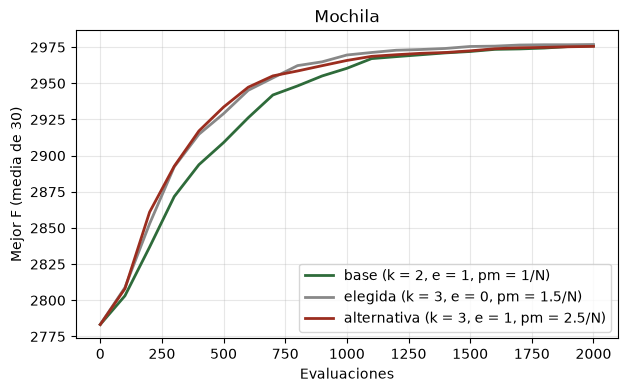

In [11]:
import matplotlib.pyplot as plt

def curva_media(cambios, semillas=SEMILLAS, paso=100):
    xs = list(range(0, 2001, paso))
    curvas = []
    for s in semillas:
        _, _, _, hist = genetico(datos, semilla=s, historial=True, **{**BASE, **cambios})
        curvas.append([max([m for ev, m in hist if ev <= x], default=hist[0][1]) for x in xs])
    return xs, [statistics.mean(c[i] for c in curvas) for i in range(len(xs))]

plt.figure(figsize=(7, 4))
for etiqueta, cambios, color in [("base (k = 2, e = 1, pm = 1/N)", {}, "#2E6B3A"), ("elegida (k = 3, e = 0, pm = 1.5/N)", dict(k=3,e=0,pm=1.5/N), "#888888"),
                                 ("alternativa (k = 3, e = 1, pm = 2.5/N)", dict(k=3, pm = 2.5/N), "#9B2D1F")]:
    xs, ys = curva_media(cambios)
    plt.plot(xs, ys, label=etiqueta, color=color, linewidth=2)
plt.xlabel("Evaluaciones"); plt.ylabel("Mejor F (media de 30)")
plt.title("Mochila"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

## FASE 6 · VALIDACIÓN

Tomaremos las tres combinaciones que dijimos previamente para compararlas entre ellas y tomaremos la que llamamos elegida. 

Notese que aunque hemos destacado que la diferencia entre configuraciones no es realmente notable, tenemos que escoger una, y para ello tomamos la que sale primera en el ranking del factorial. 

Destacamos que la mejora sigue siendo notable con respecto a la configuración inical. Además, viendo la gráfica anterior vemos que alcanza valores de f mejores con menos evaluaciones. 

Por ello, con un presupuesto menor nuestra configuración base sería mucho peor que cualquiera de las otras dos tomadas. 

In [12]:
NUEVAS = range(100, 130)
for nombre, cfg in [("base (k = 2, e = 1, pm = 1/N)", {}), ("elegida (k = 3, e = 0, pm = 1.5/N)", dict(k=3,e=0,pm=1.5/N)),
                    ("alternativa (k = 3, e = 1, pm = 2.5/N)", dict(k=3, pm = 2.5/N))]:
    r = resumen(experimento(fase = "Final", semillas=NUEVAS, **cfg))
    print(f"{nombre:40s} media = {r['media']:.2f}   sd = {r['sd']:.2f}")

base (k = 2, e = 1, pm = 1/N)            media = 2974.73   sd = 4.56
elegida (k = 3, e = 0, pm = 1.5/N)       media = 2975.83   sd = 4.22
alternativa (k = 3, e = 1, pm = 2.5/N)   media = 2975.07   sd = 3.82


## FASE 7 · CONCLUSIONES Y CONFIGURACIÓN FINAL

### Configuración final congelada

Tras analizar los resultados de los experimentos y realizar la validación con semillas distintas de las utilizadas durante el ajuste, elegimos la siguiente configuración del algoritmo genético para el problema de la mochila:

| Parámetro | Valor elegido |
|---|---|
| Tamaño de la población (\(P\)) | 50 |
| Probabilidad de cruce (\(pc\)) | 0,9 |
| Probabilidad de mutación (\(pm\)) | \(1.5/n = 0.015\) |
| Tamaño del torneo (\(k\)) | 3 |
| Elitismo (\(e\)) | 0 |
| Tipo de cruce | Uniforme |
| Tratamiento de las restricciones | Reparación |
| Presupuesto de evaluaciones | 2000 por ejecución |
| Número de ejecuciones de validación | 30 |
| Semillas de validación | 100–129 |

La reparación elimina objetos hasta que la solución cumple la capacidad máxima de la mochila. De este modo, las soluciones utilizadas para calcular el mejor valor son factibles.

### Resultados de la validación

La configuración elegida se ha evaluado con 30 semillas nuevas, reservadas para la validación. Los resultados obtenidos son los siguientes:

| Configuración | Media del mejor valor | Desviación típica | Gap medio |
|---|---:|---:|---:|
| Base: \(k=2,\ e=1,\ p_m=1/n\) | 2974,73 | 4,56 | 0,21 % |
| **Elegida: \(k=3,\ e=0,\ p_m=1.5/n\)** | **2975,83** | **4,22** | **0,17 %** |
| Alternativa: \(k=3,\ e=1,\ p_m=2.5/n\) | 2975,07 | 3,82 | 0,20 % |

El *gap* se calcula respecto al óptimo teórico de 2981 mediante:

$$
\text{Gap}(\%)=\frac{2981-\text{valor medio}}{2981}\cdot100
$$

La configuración elegida obtiene un valor medio de 2975,83 y un *gap* aproximado del 0,17 %, por lo que queda muy cerca del óptimo. Además, mejora la media de la configuración base en 1,10 unidades. La alternativa obtiene una desviación típica algo menor, pero su media es inferior a la de la configuración elegida.

Estas diferencias son pequeñas, por lo que no debemos interpretar la configuración elegida como una mejora estadísticamente demostrada sobre las otras dos. La escogemos porque ocupó el primer puesto en el ranking del experimento factorial, que combina el rendimiento medio y la estabilidad de los resultados. La validación con nuevas semillas permite comprobar que su buen comportamiento se mantiene fuera de los experimentos de ajuste.

### Qué hemos aprendido sobre los factores

Los experimentos muestran que no todos los parámetros tienen la misma influencia en este problema.

- **Tipo de cruce:** es uno de los factores más importantes. El cruce uniforme mejoró claramente los resultados respecto al cruce de un punto, por lo que decidimos utilizarlo como base para los experimentos posteriores.

- **Tamaño de la población:** aumentar la población no garantiza una mejora. Con un presupuesto fijo de 2000 evaluaciones, una población demasiado grande consume una parte importante de este presupuesto en cada generación y deja menos oportunidades para evolucionar. En nuestras pruebas, \(P=200\) obtuvo resultados claramente peores que la configuración base.

- **Probabilidad de mutación:** una mutación excesiva perjudica la búsqueda, mientras que una probabilidad moderada funciona mejor. La configuración elegida utiliza \(p_m=1.5/n\), que ofrece un buen equilibrio en el experimento factorial. Esto no demuestra que sea el valor óptimo para cualquier problema.

- **Tamaño del torneo:** aumentar \(k\) no produce necesariamente una mejora. Un torneo mayor aumenta la presión de selección, pero también puede reducir la diversidad de la población. Aunque \(k=3\) no mejoró significativamente la configuración base en el experimento individual, sí formó parte de la mejor combinación del factorial.

- **Elitismo:** no observamos diferencias significativas al cambiar el número de individuos conservados en los experimentos individuales. Por tanto, no podemos afirmar que este factor sea determinante. El factorial favoreció la combinación con \(e=0\), que finalmente hemos elegido.

- **Probabilidad de cruce:** reducirla a \(pc=0.6\) empeoró significativamente los resultados, mientras que \(pc=1.0\) no mostró una diferencia significativa respecto a \(pc=0.9\). Por tanto, una probabilidad alta parece adecuada, aunque los experimentos no demuestran que \(0.9\) sea superior a \(1.0\).

- **Tratamiento de las restricciones:** fue uno de los factores más determinantes. La reparación obtuvo resultados mucho mejores que las penalizaciones probadas. Estas últimas dependieron bastante del valor de \(\lambda\), y ninguna alcanzó el óptimo en las 30 ejecuciones de las configuraciones estudiadas.

Por último, no hemos podido comprobar directamente la hipótesis sobre la interacción entre el tamaño de la población y la mutación, ya que el experimento factorial realizado combinó \(pm\), \(k\) y \(e\), pero no \(P\) y \(pm\).

### Comparación con la práctica de los bloques

En la práctica de los bloques también comprobamos que no existe un algoritmo que sea necesariamente el mejor en todos los casos. El rendimiento dependía de la función objetivo y de los parámetros empleados. En esta práctica aparece una idea similar: el resultado depende de cómo se combinen los operadores y parámetros del algoritmo genético.

Sin embargo, hay una diferencia importante. En la práctica de los bloques comparamos distintos algoritmos de búsqueda local y sus mecanismos de aceptación, mientras que aquí estudiamos principalmente cómo influyen la población, el cruce, la mutación, la selección, el elitismo y la reparación de soluciones no factibles dentro de un mismo algoritmo genético.

Además, en ambos trabajos es fundamental mantener las condiciones experimentales controladas, utilizar un presupuesto de evaluaciones comparable y separar las semillas de ajuste de las de validación. De esta manera evitamos elegir una configuración únicamente porque haya obtenido un resultado favorable por azar en unas pocas ejecuciones.

### Conclusión final

La principal enseñanza de esta práctica es que **el rendimiento de un algoritmo genético depende tanto de sus operadores como de la combinación de sus parámetros y de las características del problema**. En nuestro problema de la mochila, el cruce uniforme y la reparación de las soluciones han resultado especialmente importantes, mientras que los cambios individuales en el elitismo han tenido una influencia menos clara.

La configuración final elegida utiliza una población de 50 individuos, cruce uniforme con probabilidad 0,9, mutación \(1.5/n\), torneo de tamaño 3, sin elitismo y reparación de las soluciones. Con un presupuesto de 2000 evaluaciones, obtiene un valor medio de 2975,83 y un *gap* de aproximadamente el 0,17 % en la validación.

Aunque no podemos asegurar que esta combinación sea la mejor posible, los resultados muestran que es una elección sólida para las configuraciones estudiadas. Al igual que en la práctica de los bloques, no basta con elegir un algoritmo o aumentar indiscriminadamente sus parámetros: hay que experimentar, comparar los resultados y seleccionar la configuración que mejor se adapte al problema concreto.

